# SHAP Analizi — LightGBM Optuna V2 (NaN Native)
## IEEE-CIS Fraud Detection | Model Açıklanabilirliği

**Amaç:** En iyi LightGBM modelinin (Optuna V2, AUC-PR=0.6307) SHAP değerleriyle açıklanması.

**Pipeline:** LGB Optuna V2 ile özdeş — leakage-free, aynı özellik mühendisliği.

| SHAP Grafiği | Açıklama |
|---|---|
| Beeswarm | Tüm özellikler için SHAP dağılımı (Top 20) |
| Bar (mean \|SHAP\|) | Ortalama mutlak SHAP — global önem sıralaması |
| Waterfall (Fraud) | Tek bir fraud işleminin kararı adım adım |
| Waterfall (Normal) | Tek bir normal işleminin kararı adım adım |

**Kaydedilen dosyalar:** shap_beeswarm.png, shap_bar.png, shap_waterfall_fraud.png,
shap_waterfall_normal.png, shap_top_features.csv

## 1. Kütüphaneler

In [1]:
import os, gc, time, warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

import lightgbm as lgb
import joblib
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    precision_recall_curve, confusion_matrix,
)

try:
    import shap
except ImportError:
    import subprocess
    subprocess.run(['pip', 'install', 'shap', '-q'], check=True)
    import shap

warnings.filterwarnings('ignore')
matplotlib.rcParams['figure.figsize'] = (12, 5)
sns.set_style('whitegrid')

_t0_total = time.time()
print(f'LightGBM : {lgb.__version__}')
print(f'SHAP     : {shap.__version__}')
print('Kutuphaneler yuklendi.')

LightGBM : 4.6.0
SHAP     : 0.51.0
Kutuphaneler yuklendi.


## 2. Bellek Optimizasyonu

In [2]:
def reduce_mem_usage(df: pd.DataFrame, verbose: bool = True) -> pd.DataFrame:
    """Sayisal sutunlarin veri tipini kuculterek RAM kullanimi azaltir."""
    start_mem = df.memory_usage(deep=True).sum() / 1024**2
    for col in df.columns:
        col_type = df[col].dtype
        if col_type == object:
            continue
        c_min, c_max = df[col].min(), df[col].max()
        if str(col_type)[:3] == 'int':
            if c_min > np.iinfo(np.int8).min and c_max < np.iinfo(np.int8).max:
                df[col] = df[col].astype(np.int8)
            elif c_min > np.iinfo(np.int16).min and c_max < np.iinfo(np.int16).max:
                df[col] = df[col].astype(np.int16)
            elif c_min > np.iinfo(np.int32).min and c_max < np.iinfo(np.int32).max:
                df[col] = df[col].astype(np.int32)
            else:
                df[col] = df[col].astype(np.int64)
        else:
            if c_min > np.finfo(np.float32).min and c_max < np.finfo(np.float32).max:
                df[col] = df[col].astype(np.float32)
            else:
                df[col] = df[col].astype(np.float64)
    end_mem = df.memory_usage(deep=True).sum() / 1024**2
    if verbose:
        print(
            f'Bellek: {start_mem:.1f} MB -> {end_mem:.1f} MB '
            f'({100*(start_mem - end_mem)/start_mem:.1f}% azaldi)'
        )
    return df

## 3. Veri Yükleme

In [3]:
_t_start = time.time()

from google.colab import drive
drive.mount('/content/drive')

DRIVE_DATA_PATH = '/content/drive/My Drive/Bitirme/VeriSeti'
TRAIN_PATH = f'{DRIVE_DATA_PATH}/train_transaction.csv'
IDENT_PATH = f'{DRIVE_DATA_PATH}/train_identity.csv'

# Cikti klasoru (model ve sonuclar burada)
SAVE_BASE = '/content/drive/My Drive/Bitirme/15-Mayıs-Cuma/'
os.makedirs(SAVE_BASE, exist_ok=True)
print(f'Cikti klasoru : {SAVE_BASE}')

assert os.path.exists(TRAIN_PATH), f'HATA: {TRAIN_PATH}'
assert os.path.exists(IDENT_PATH), f'HATA: {IDENT_PATH}'

MODEL_PATH = SAVE_BASE + 'lgb_optuna_v2_model.pkl'
assert os.path.exists(MODEL_PATH), f'HATA: Model bulunamadi -> {MODEL_PATH}'
print(f'Model dosyasi : {MODEL_PATH} [BULUNDU]')

df_tx = pd.read_csv(TRAIN_PATH)
df_id = pd.read_csv(IDENT_PATH)
df = df_tx.merge(df_id, on='TransactionID', how='left')
del df_tx, df_id
gc.collect()

df = reduce_mem_usage(df)
print(f'Veri seti: {df.shape[0]:,} satir x {df.shape[1]} sutun')
print(f'Fraud orani: {df.isFraud.mean()*100:.2f}%')
print(f'[SURE] Veri yukleme: {time.time()-_t_start:.1f} sn')

Mounted at /content/drive
Cikti klasoru : /content/drive/My Drive/Bitirme/15-Mayıs-Cuma/
Model dosyasi : /content/drive/My Drive/Bitirme/15-Mayıs-Cuma/lgb_optuna_v2_model.pkl [BULUNDU]
Bellek: 2514.0 MB -> 1603.3 MB (36.2% azaldi)
Veri seti: 590,540 satir x 434 sutun
Fraud orani: 3.50%
[SURE] Veri yukleme: 70.3 sn


## 4. Veri Temizleme ve Kategorik Encoding

**NaN stratejisi:** LGB Optuna V2 ile özdeş — sayısal NaN'lar değiştirilmez.

In [4]:
_t_start = time.time()

MISSING_THRESHOLD = 0.80
missing_pct = df.isnull().mean()
df_clean = df.loc[:, missing_pct <= MISSING_THRESHOLD].copy()
print(f'{df.shape[1] - df_clean.shape[1]} sutun atildi (>%80 bos)')
print(f'Kalan sutun: {df_clean.shape[1]}')

cat_cols = df_clean.select_dtypes(include='object').columns.tolist()
for col in cat_cols:
    df_clean[col] = df_clean[col].fillna('bilinmiyor')

le = LabelEncoder()
for col in cat_cols:
    df_clean[col] = le.fit_transform(df_clean[col].astype(str))

df_clean = reduce_mem_usage(df_clean, verbose=False)
print('Temizlik tamamlandi.')
print(f'[SURE] Temizlik: {time.time()-_t_start:.1f} sn')

74 sutun atildi (>%80 bos)
Kalan sutun: 360
Temizlik tamamlandi.
[SURE] Temizlik: 9.7 sn


## 5. Zaman ve Harcama Özellikleri

In [5]:
_t_start = time.time()

df_clean['tx_hour']     = (df_clean['TransactionDT'] % 86400) // 3600
df_clean['is_night']    = (
    (df_clean['tx_hour'] >= 0) & (df_clean['tx_hour'] < 9)
).astype(np.int8)
df_clean['tx_day']      = df_clean['TransactionDT'] // 86400
df_clean['day_of_week'] = (df_clean['TransactionDT'] // 86400) % 7
df_clean['log_amt']     = np.log1p(df_clean['TransactionAmt']).astype(np.float32)
df_clean['amt_dollars'] = df_clean['TransactionAmt'].astype(np.int32)
df_clean['amt_cents']   = (
    (df_clean['TransactionAmt'] % 1) * 100
).round().astype(np.int8)

print('Zaman ve harcama ozellikleri eklendi.')
print(f'[SURE] Zaman ozellikleri: {time.time()-_t_start:.1f} sn')

Zaman ve harcama ozellikleri eklendi.
[SURE] Zaman ozellikleri: 0.1 sn


## 6. Temporal Split (%80 Train / %20 Test, Kronolojik)

In [6]:
_t_start = time.time()

split_idx = int(len(df_clean) * 0.80)
DROP_COLS_EARLY = ['TransactionID', 'isFraud']

X_train = (
    df_clean.iloc[:split_idx]
    .drop(columns=DROP_COLS_EARLY)
    .copy()
    .reset_index(drop=True)
)
y_train = df_clean.iloc[:split_idx]['isFraud'].reset_index(drop=True)

X_test = (
    df_clean.iloc[split_idx:]
    .drop(columns=DROP_COLS_EARLY)
    .copy()
    .reset_index(drop=True)
)
y_test = df_clean.iloc[split_idx:]['isFraud'].reset_index(drop=True)

print(f'Egitim seti : {X_train.shape[0]:,} islem | Fraud: {y_train.mean()*100:.2f}%')
print(f'Test seti   : {X_test.shape[0]:,} islem  | Fraud: {y_test.mean()*100:.2f}%')
del df_clean, df
gc.collect()
print(f'[SURE] Temporal split: {time.time()-_t_start:.1f} sn')

Egitim seti : 472,432 islem | Fraud: 3.51%
Test seti   : 118,108 islem  | Fraud: 3.44%
[SURE] Temporal split: 2.7 sn


## 7. Kronolojik Sıralama

In [7]:
_t_start = time.time()

sort_idx_train = X_train['TransactionDT'].argsort(kind='stable')
X_train = X_train.iloc[sort_idx_train].reset_index(drop=True)
y_train = y_train.iloc[sort_idx_train].reset_index(drop=True)

sort_idx_test = X_test['TransactionDT'].argsort(kind='stable')
X_test = X_test.iloc[sort_idx_test].reset_index(drop=True)
y_test = y_test.iloc[sort_idx_test].reset_index(drop=True)

print('TransactionDT siralamasi tamamlandi.')
print(f'[SURE] Siralama: {time.time()-_t_start:.1f} sn')

TransactionDT siralamasi tamamlandi.
[SURE] Siralama: 0.7 sn


## 8. V Sütunu Grup Seçimi (n_per_group=5)

In [8]:
_t_start = time.time()

try:
    from tqdm.auto import tqdm as _tqdm
except ImportError:
    import subprocess
    subprocess.run(['pip', 'install', 'tqdm', '-q'], check=True)
    from tqdm.auto import tqdm as _tqdm


def select_v_features(
    X_train: pd.DataFrame,
    y_train: pd.Series,
    n_per_group: int = 5,
    bucket_size: float = 0.05,
    min_valid_samples: int = 500,
) -> list:
    v_cols = [c for c in X_train.columns if c.startswith('V')]
    if not v_cols:
        return []
    missing_rates = X_train[v_cols].isnull().mean()
    buckets = (missing_rates / bucket_size).astype(int)
    selected = []
    for bucket_id in _tqdm(sorted(buckets.unique()), desc='V grup secimi', unit='grup'):
        cols_in_bucket = buckets[buckets == bucket_id].index.tolist()
        corr_dict = {}
        for col in cols_in_bucket:
            valid_mask = X_train[col].notna()
            if valid_mask.sum() < min_valid_samples:
                continue
            corr_val = abs(X_train.loc[valid_mask, col].corr(y_train[valid_mask]))
            if not np.isnan(corr_val):
                corr_dict[col] = corr_val
        top_cols = sorted(corr_dict, key=corr_dict.get, reverse=True)[:n_per_group]
        selected.extend(top_cols)
    return selected


all_v_cols = [c for c in X_train.columns if c.startswith('V')]
v_selected = select_v_features(X_train, y_train, n_per_group=5)
v_to_drop  = [c for c in all_v_cols if c not in v_selected]
X_train.drop(columns=v_to_drop, inplace=True)
X_test.drop(columns=v_to_drop, inplace=True)

print(f'V secimi: {len(v_selected)} sutun kaldi, {len(v_to_drop)} atildi.')
print(f'[SURE] V sutun secimi: {time.time()-_t_start:.1f} sn')

V grup secimi:   0%|          | 0/6 [00:00<?, ?grup/s]

V secimi: 30 sutun kaldi, 262 atildi.
[SURE] V sutun secimi: 3.7 sn


## 9. D Sütunu Normalizasyonu (Chris Deotte Yöntemi)

In [9]:
_t_start = time.time()

D_SKIP = {1, 2, 3, 5, 9}

def engineer_d_features(X_train, X_test):
    normalized = []
    for i in range(1, 16):
        if i in D_SKIP:
            continue
        col = f'D{i}'
        if col not in X_train.columns:
            continue
        norm_col = f'{col}_norm'
        tx_day_train = X_train['TransactionDT'] / np.float32(86400)
        tx_day_test  = X_test['TransactionDT']  / np.float32(86400)
        X_train[norm_col] = (X_train[col] - tx_day_train).astype(np.float32)
        X_test[norm_col]  = (X_test[col]  - tx_day_test).astype(np.float32)
        normalized.append(col)
    print(f'D normalizasyonu: {len(normalized)} sutun icin norm ozelligi eklendi.')
    return X_train, X_test


X_train, X_test = engineer_d_features(X_train, X_test)
print(f'[SURE] D normalizasyon: {time.time()-_t_start:.1f} sn')

D normalizasyonu: 4 sutun icin norm ozelligi eklendi.
[SURE] D normalizasyon: 0.0 sn


## 10. D1n Hesaplama ve UID Oluşturma

In [10]:
_t_start = time.time()

if 'D1' in X_train.columns:
    X_train['D1n'] = np.floor(X_train['tx_day'] - X_train['D1']).astype(np.float32)
    X_test['D1n']  = np.floor(X_test['tx_day']  - X_test['D1']).astype(np.float32)
else:
    X_train['D1n'] = np.nan
    X_test['D1n']  = np.nan

uid_train = (
    X_train['card1'].astype(str) + '_' +
    X_train['addr1'].fillna(-1).astype(int).astype(str) + '_' +
    X_train['D1n'].fillna(-999).astype(int).astype(str)
)
uid_test = (
    X_test['card1'].astype(str) + '_' +
    X_test['addr1'].fillna(-1).astype(int).astype(str) + '_' +
    X_test['D1n'].fillna(-999).astype(int).astype(str)
)

print(f'Benzersiz UID (train): {uid_train.nunique():,}')
print(f'Benzersiz UID (test) : {uid_test.nunique():,}')
print(f'[SURE] D1n ve UID: {time.time()-_t_start:.1f} sn')

Benzersiz UID (train): 182,535
Benzersiz UID (test) : 57,097
[SURE] D1n ve UID: 0.7 sn


## 11. Velocity Özellikleri

In [11]:
_t_start = time.time()

def add_velocity_features(X_train, y_train, X_test, uid_train, uid_test):
    X_train = X_train.copy()
    X_test  = X_test.copy()
    X_train['_uid'] = uid_train.values
    X_test['_uid']  = uid_test.values

    X_train['uid_tx_count'] = (
        X_train.groupby('_uid').cumcount()
    ).astype(np.float32)

    for col, out_name in [
        ('TransactionAmt', 'uid_amt_mean'),
        ('TransactionAmt', 'uid_amt_std'),
        ('tx_hour',        'uid_hour_mean'),
    ]:
        if col not in X_train.columns:
            continue
        if out_name.endswith('_std'):
            X_train[out_name] = (
                X_train.groupby('_uid')[col]
                .transform(lambda x: x.expanding().std().shift(1))
                .astype(np.float32)
            )
        else:
            X_train[out_name] = (
                X_train.groupby('_uid')[col]
                .transform(lambda x: x.expanding().mean().shift(1))
                .astype(np.float32)
            )

    X_train['_target'] = y_train.values
    X_train['uid_fraud_mean'] = (
        X_train.groupby('_uid')['_target']
        .transform(lambda x: x.expanding().mean().shift(1))
        .astype(np.float32)
    )
    uid_fraud_rate_map = X_train.groupby('_uid')['_target'].mean()
    X_train.drop(columns=['_target'], inplace=True)

    uid_stats_train = X_train.groupby('_uid').agg(
        uid_amt_mean_base=('TransactionAmt', 'mean'),
        uid_amt_std_base=('TransactionAmt', 'std'),
        uid_hour_mean_base=('tx_hour', 'mean'),
        uid_tx_count_base=('TransactionAmt', 'count'),
    )
    X_test['uid_tx_count']   = X_test['_uid'].map(uid_stats_train['uid_tx_count_base']).astype(np.float32)
    X_test['uid_amt_mean']   = X_test['_uid'].map(uid_stats_train['uid_amt_mean_base']).astype(np.float32)
    X_test['uid_amt_std']    = X_test['_uid'].map(uid_stats_train['uid_amt_std_base']).astype(np.float32)
    X_test['uid_hour_mean']  = X_test['_uid'].map(uid_stats_train['uid_hour_mean_base']).astype(np.float32)
    X_test['uid_fraud_mean'] = X_test['_uid'].map(uid_fraud_rate_map).astype(np.float32)

    X_train.drop(columns=['_uid'], inplace=True)
    X_test.drop(columns=['_uid'], inplace=True)
    print('Velocity ozellikleri eklendi.')
    return X_train, X_test


X_train, X_test = add_velocity_features(X_train, y_train, X_test, uid_train, uid_test)
print(f'[SURE] Velocity ozellikleri: {time.time()-_t_start:.1f} sn')

Velocity ozellikleri eklendi.
[SURE] Velocity ozellikleri: 180.5 sn


## 12. UID Statik Agregasyonlar ve M Sütunu Ortalamaları

In [12]:
_t_start = time.time()

def add_uid_aggregations(X_train, X_test, uid_train, uid_test):
    X_train = X_train.copy()
    X_test  = X_test.copy()
    X_train['_uid'] = uid_train.values
    X_test['_uid']  = uid_test.values

    uid_agg = X_train.groupby('_uid').agg(
        uid_mean_amt=('TransactionAmt', 'mean'),
        uid_std_amt=('TransactionAmt', 'std'),
        uid_count=('TransactionAmt', 'count'),
        uid_max_amt=('TransactionAmt', 'max'),
    )
    if 'card2' in X_train.columns:
        uid_agg['uid_nunique_card2'] = X_train.groupby('_uid')['card2'].nunique()

    for col in uid_agg.columns:
        X_train[col] = X_train['_uid'].map(uid_agg[col]).astype(np.float32)
        X_test[col]  = X_test['_uid'].map(uid_agg[col]).astype(np.float32)

    X_train.drop(columns=['_uid'], inplace=True)
    X_test.drop(columns=['_uid'], inplace=True)
    print(f'UID statik agregasyon tamamlandi.')
    return X_train, X_test


def add_m_uid_means(X_train, X_test, uid_train, uid_test):
    X_train = X_train.copy()
    X_test  = X_test.copy()
    X_train['_uid'] = uid_train.values
    X_test['_uid']  = uid_test.values

    m_cols = [c for c in X_train.columns if c.startswith('M') and c[1:].isdigit()]
    added = []
    for col in m_cols:
        out_col = f'uid_{col}_mean'
        uid_m_mean = X_train.groupby('_uid')[col].mean()
        X_train[out_col] = X_train['_uid'].map(uid_m_mean).astype(np.float32)
        X_test[out_col]  = X_test['_uid'].map(uid_m_mean).astype(np.float32)
        added.append(out_col)

    X_train.drop(columns=['_uid'], inplace=True)
    X_test.drop(columns=['_uid'], inplace=True)
    print(f'M-UID ortalamalari ({len(added)} ozellik) eklendi.')
    return X_train, X_test


X_train, X_test = add_uid_aggregations(X_train, X_test, uid_train, uid_test)
X_train, X_test = add_m_uid_means(X_train, X_test, uid_train, uid_test)
print(f'[SURE] UID agregasyon + M ortalamalari: {time.time()-_t_start:.1f} sn')

UID statik agregasyon tamamlandi.
M-UID ortalamalari (9 ozellik) eklendi.
[SURE] UID agregasyon + M ortalamalari: 5.4 sn


## 13. Tutar Ratio ve Z-Score Özellikleri

In [13]:
_t_start = time.time()

def add_amount_ratio_features(X_train, X_test):
    for df_ in [X_train, X_test]:
        if 'uid_mean_amt' in df_.columns:
            df_['amt_ratio'] = (
                df_['TransactionAmt'] / (df_['uid_mean_amt'] + 1e-6)
            ).astype(np.float32)
        if 'uid_mean_amt' in df_.columns and 'uid_std_amt' in df_.columns:
            df_['amt_zscore'] = (
                (df_['TransactionAmt'] - df_['uid_mean_amt']) /
                (df_['uid_std_amt'].fillna(1.0) + 1e-6)
            ).astype(np.float32)
    print('Tutar ratio ozellikleri eklendi: amt_ratio, amt_zscore')
    return X_train, X_test


X_train, X_test = add_amount_ratio_features(X_train, X_test)
print(f'Toplam ozellik sayisi: {X_train.shape[1]}')
print(f'[SURE] Tutar ratio: {time.time()-_t_start:.1f} sn')

Tutar ratio ozellikleri eklendi: amt_ratio, amt_zscore
Toplam ozellik sayisi: 129
[SURE] Tutar ratio: 0.0 sn


## 14. UID Target Encoding — Val Split'ten ÖNCE

In [14]:
_t_start = time.time()

def add_uid_target_encoding(X_train, y_train, X_test, uid_train, uid_test):
    X_train = X_train.copy()
    X_test  = X_test.copy()
    X_train['_uid']    = uid_train.values
    X_test['_uid']     = uid_test.values
    X_train['_target'] = y_train.values

    X_train['uid_target_enc'] = (
        X_train.groupby('_uid')['_target']
        .transform(lambda x: x.expanding().mean().shift(1))
        .astype(np.float32)
    )
    uid_fraud_rate = X_train.groupby('_uid')['_target'].mean()
    X_test['uid_target_enc'] = X_test['_uid'].map(uid_fraud_rate).astype(np.float32)

    X_train.drop(columns=['_uid', '_target'], inplace=True)
    X_test.drop(columns=['_uid'], inplace=True)
    print('UID target encoding tamamlandi (val-split oncesi, leakage-free)')
    return X_train, X_test


X_train, X_test = add_uid_target_encoding(X_train, y_train, X_test, uid_train, uid_test)
print(f'Toplam ozellik sayisi: {X_train.shape[1]}')
print(f'[SURE] UID target encoding: {time.time()-_t_start:.1f} sn')

UID target encoding tamamlandi (val-split oncesi, leakage-free)
Toplam ozellik sayisi: 130
[SURE] UID target encoding: 43.5 sn


## 15. Validation Split (Kronolojik Son %20)

In [15]:
_t_start = time.time()

val_split_idx = int(len(X_train) * 0.80)
X_tr  = X_train.iloc[:val_split_idx].copy()
y_tr  = y_train.iloc[:val_split_idx].copy()
X_val = X_train.iloc[val_split_idx:].copy()
y_val = y_train.iloc[val_split_idx:].copy()

uid_tr  = uid_train.iloc[:val_split_idx].reset_index(drop=True)
uid_val = uid_train.iloc[val_split_idx:].reset_index(drop=True)

for df_ in [X_tr, X_val, X_test]:
    if 'TransactionDT' in df_.columns:
        df_.drop(columns=['TransactionDT'], inplace=True)

print(f'X_tr  : {X_tr.shape[0]:,} satir | Fraud: {y_tr.mean()*100:.2f}%')
print(f'X_val : {X_val.shape[0]:,} satir | Fraud: {y_val.mean()*100:.2f}%')
print(f'X_test: {X_test.shape[0]:,} satir | Fraud: {y_test.mean()*100:.2f}%')
print(f'Toplam ozellik: {X_tr.shape[1]}')
print(f'[SURE] Val split: {time.time()-_t_start:.1f} sn')

X_tr  : 377,945 satir | Fraud: 3.41%
X_val : 94,487 satir | Fraud: 3.92%
X_test: 118,108 satir | Fraud: 3.44%
Toplam ozellik: 129
[SURE] Val split: 0.2 sn


## 16. Kategorik Target Encoding — Val Split'ten SONRA

In [16]:
_t_start = time.time()

def add_categorical_target_encoding(X_tr, y_tr, X_val, X_test, cat_cols=None):
    if cat_cols is None:
        cat_cols = [c for c in ['card1', 'card4', 'card6', 'ProductCD',
                                 'P_emaildomain', 'R_emaildomain']
                    if c in X_tr.columns]
    global_fraud_rate = float(y_tr.mean())
    te_cols = []
    for col in cat_cols:
        out_col = f'{col}_target_enc'
        temp = pd.DataFrame({'_cat': X_tr[col].values, '_target': y_tr.values})
        fraud_rate_map = temp.groupby('_cat')['_target'].mean()
        X_tr[out_col]   = X_tr[col].map(fraud_rate_map).fillna(global_fraud_rate).astype(np.float32)
        X_val[out_col]  = X_val[col].map(fraud_rate_map).fillna(global_fraud_rate).astype(np.float32)
        X_test[out_col] = X_test[col].map(fraud_rate_map).fillna(global_fraud_rate).astype(np.float32)
        te_cols.append(out_col)
    print(f'Kategorik TE tamamlandi: {te_cols}')
    return X_tr, X_val, X_test


X_tr, X_val, X_test = add_categorical_target_encoding(X_tr, y_tr, X_val, X_test)
print(f'Final ozellik sayisi (X_tr): {X_tr.shape[1]}')
assert X_tr.shape[1] == X_val.shape[1] == X_test.shape[1], 'Sutun sayisi eslesmiyor!'
print('Ozellik dogrulamasi: GECTI')
print(f'[SURE] Kategorik TE: {time.time()-_t_start:.1f} sn')

Kategorik TE tamamlandi: ['card1_target_enc', 'card4_target_enc', 'card6_target_enc', 'ProductCD_target_enc', 'P_emaildomain_target_enc', 'R_emaildomain_target_enc']
Final ozellik sayisi (X_tr): 135
Ozellik dogrulamasi: GECTI
[SURE] Kategorik TE: 0.1 sn


## 17. Model Yükleme

LGB Optuna V2 modeli Drive'dan yüklenir.  
Model `lgb_optuna_v2_model.pkl` — test AUC-PR = 0.6307, AUC-ROC = 0.9179.

In [17]:
_t_start = time.time()

lgb_model = joblib.load(MODEL_PATH)
print(f'Model yuklendi: {MODEL_PATH}')
print(f'  best_iteration : {lgb_model.best_iteration_}')
print(f'  n_estimators   : {lgb_model.n_estimators}')
print(f'  num_leaves     : {lgb_model.num_leaves}')

# Model dogrulama — test AUC-PR'yi tekrar hesapla
test_proba   = lgb_model.predict_proba(X_test)[:, 1]
test_auc_pr  = average_precision_score(y_test, test_proba)
test_auc_roc = roc_auc_score(y_test, test_proba)
print(f'  Test AUC-PR    : {test_auc_pr:.4f}  (beklenen: ~0.6307)')
print(f'  Test AUC-ROC   : {test_auc_roc:.4f}  (beklenen: ~0.9179)')

assert abs(test_auc_pr - 0.6307) < 0.005, \
    f'AUC-PR beklenenden farkli: {test_auc_pr:.4f}'
print('Model dogrulama: GECTI')
print(f'[SURE] Model yukleme: {time.time()-_t_start:.1f} sn')

Model yuklendi: /content/drive/My Drive/Bitirme/15-Mayıs-Cuma/lgb_optuna_v2_model.pkl
  best_iteration : 2106
  n_estimators   : 3000
  num_leaves     : 462
  Test AUC-PR    : 0.6307  (beklenen: ~0.6307)
  Test AUC-ROC   : 0.9179  (beklenen: ~0.9179)
Model dogrulama: GECTI
[SURE] Model yukleme: 73.9 sn


## 18. SHAP — Örneklem Seçimi (Stratified 2000 Satır)

SHAP hesaplaması tüm test seti yerine stratified örneklem üzerinde yapılır:
- ~500 fraud (tüm fraudlar varsa kullan)
- ~1500 normal işlem (rastgele sample)

Bu yaklaşım: SHAP değerlerini temsil gücü yüksek tutarken hesaplama süresini düşürür.

In [18]:
_t_start = time.time()

np.random.seed(42)

SHAP_N_FRAUD  = 500
SHAP_N_NORMAL = 1500

fraud_idx  = np.where(y_test == 1)[0]
normal_idx = np.where(y_test == 0)[0]

# Fraud: tümünü al (ya da SHAP_N_FRAUD kadar)
if len(fraud_idx) <= SHAP_N_FRAUD:
    sampled_fraud = fraud_idx
else:
    sampled_fraud = np.random.choice(fraud_idx, size=SHAP_N_FRAUD, replace=False)

# Normal: rastgele sample
sampled_normal = np.random.choice(normal_idx, size=SHAP_N_NORMAL, replace=False)

shap_idx = np.concatenate([sampled_fraud, sampled_normal])
np.random.shuffle(shap_idx)

X_shap  = X_test.iloc[shap_idx].reset_index(drop=True)
y_shap  = y_test.iloc[shap_idx].reset_index(drop=True)

print(f'SHAP orneklemi: {len(X_shap):,} satir')
print(f'  Fraud  : {y_shap.sum():,} ({y_shap.mean()*100:.1f}%)')
print(f'  Normal : {(y_shap==0).sum():,} ({(1-y_shap.mean())*100:.1f}%)')
print(f'  Ozellik: {X_shap.shape[1]}')
print(f'[SURE] Orneklem: {time.time()-_t_start:.1f} sn')

SHAP orneklemi: 2,000 satir
  Fraud  : 500 (25.0%)
  Normal : 1,500 (75.0%)
  Ozellik: 135
[SURE] Orneklem: 0.0 sn


## 19. SHAP TreeExplainer

LightGBM için `shap.TreeExplainer` kullanılır — GPU/CPU'dan bağımsız, hızlı.

**Çıktı formatı notu:**  
LightGBM binary classification'da `explainer.shap_values()` bazen liste döner  
(binary output → [neg_class_shap, pos_class_shap]).  
Fraud sınıfı (pozitif) için indeks 1 seçilir.

In [19]:
_t_start = time.time()

print('SHAP TreeExplainer baslatiliyor...')
explainer = shap.TreeExplainer(lgb_model)

print('SHAP degerleri hesaplaniyor (bu ~2-5 dk surebilir)...')
shap_values_raw = explainer.shap_values(X_shap)

# LightGBM binary: liste mi yoksa array mi?
if isinstance(shap_values_raw, list):
    # Liste: [neg_class, pos_class] — fraud icin pos_class al
    shap_vals = shap_values_raw[1]
    print(f'Liste formatinda: {len(shap_values_raw)} sinif, fraud (idx=1) secildi.')
else:
    shap_vals = shap_values_raw
    print(f'Array formatinda: shape={shap_vals.shape}')

print(f'SHAP deger matrisi: {shap_vals.shape}  (orneklem x ozellik)')
print(f'[SURE] SHAP hesaplama: {time.time()-_t_start:.1f} sn')

SHAP TreeExplainer baslatiliyor...
SHAP degerleri hesaplaniyor (bu ~2-5 dk surebilir)...
Array formatinda: shape=(2000, 135)
SHAP deger matrisi: (2000, 135)  (orneklem x ozellik)
[SURE] SHAP hesaplama: 2245.5 sn


## 20. SHAP Beeswarm Grafiği (Top 20 Özellik)

Her nokta bir işlemi temsil eder.  
Renk: özellik değeri (kırmızı=yüksek, mavi=düşük).  
X ekseni: SHAP değeri (pozitif → fraud olasılığını artırır).

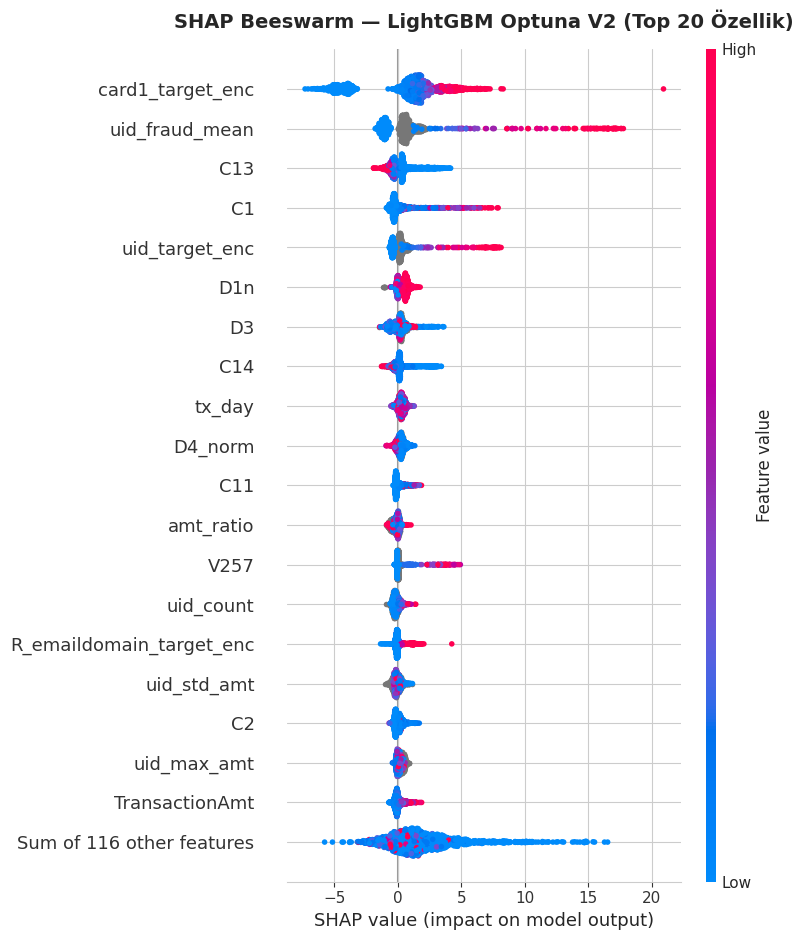

Kaydedildi: /content/drive/My Drive/Bitirme/15-Mayıs-Cuma/shap_beeswarm.png
[SURE] Beeswarm: 1.7 sn


In [20]:
_t_start = time.time()

shap_explanation = shap.Explanation(
    values=shap_vals,
    base_values=explainer.expected_value[1] if isinstance(explainer.expected_value, (list, np.ndarray)) else explainer.expected_value,
    data=X_shap.values,
    feature_names=list(X_shap.columns),
)

fig, ax = plt.subplots(figsize=(12, 9))
shap.plots.beeswarm(
    shap_explanation,
    max_display=20,
    show=False,
)
plt.title(
    'SHAP Beeswarm — LightGBM Optuna V2 (Top 20 Özellik)',
    fontsize=14, fontweight='bold', pad=15
)
plt.tight_layout()
beeswarm_path = SAVE_BASE + 'shap_beeswarm.png'
plt.savefig(beeswarm_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Kaydedildi: {beeswarm_path}')
print(f'[SURE] Beeswarm: {time.time()-_t_start:.1f} sn')

## 21. SHAP Bar Grafiği — Global Özellik Önemi (Mean |SHAP|)

Ortalama mutlak SHAP değeri → hangi özellik modelin kararını en çok etkiliyor?

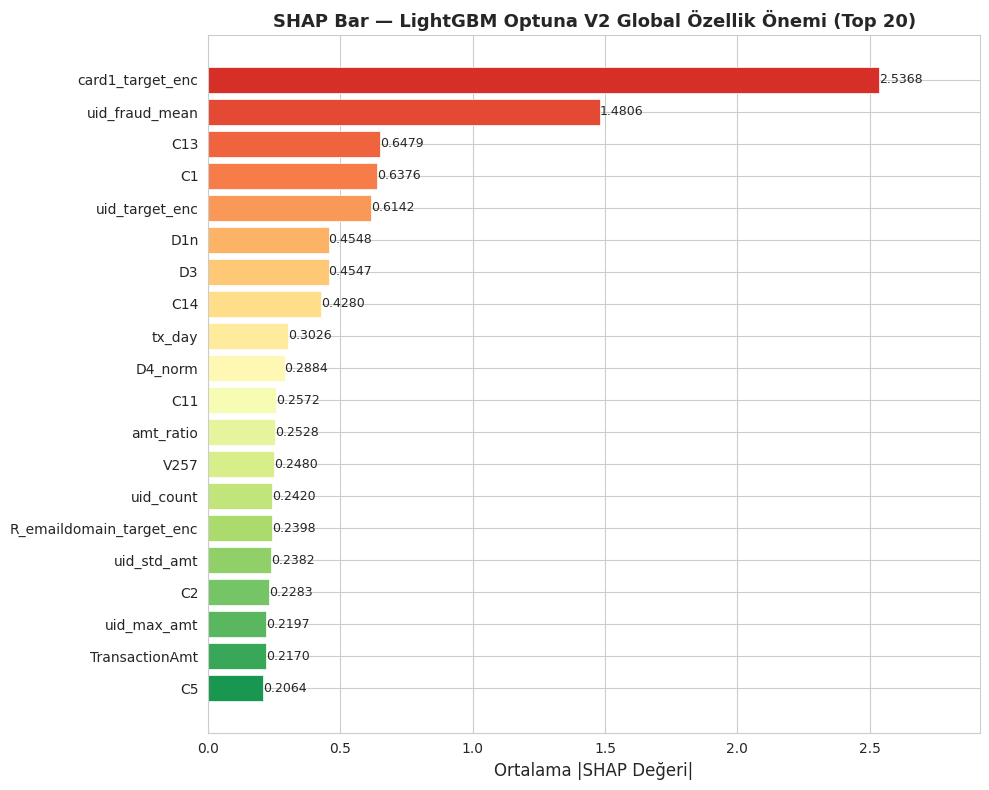

Kaydedildi: /content/drive/My Drive/Bitirme/15-Mayıs-Cuma/shap_bar.png
Kaydedildi: /content/drive/My Drive/Bitirme/15-Mayıs-Cuma/shap_top_features.csv

TOP 20 OZELLIK (Mean |SHAP|):
                 feature  mean_abs_shap
        card1_target_enc       2.536804
          uid_fraud_mean       1.480614
                     C13       0.647934
                      C1       0.637629
          uid_target_enc       0.614182
                     D1n       0.454755
                      D3       0.454746
                     C14       0.427971
                  tx_day       0.302590
                 D4_norm       0.288361
                     C11       0.257202
               amt_ratio       0.252843
                    V257       0.247998
               uid_count       0.241993
R_emaildomain_target_enc       0.239828
             uid_std_amt       0.238212
                      C2       0.228274
             uid_max_amt       0.219749
          TransactionAmt       0.216970
                  

In [21]:
_t_start = time.time()

# Mean |SHAP| hesapla
mean_abs_shap = np.abs(shap_vals).mean(axis=0)
shap_importance = pd.DataFrame({
    'feature'        : list(X_shap.columns),
    'mean_abs_shap'  : mean_abs_shap,
}).sort_values('mean_abs_shap', ascending=False).reset_index(drop=True)

TOP_N = 20
top_shap = shap_importance.head(TOP_N)

fig, ax = plt.subplots(figsize=(10, 8))
colors = plt.cm.RdYlGn_r(np.linspace(0.1, 0.9, TOP_N))
bars = ax.barh(
    top_shap['feature'][::-1],
    top_shap['mean_abs_shap'][::-1],
    color=colors,
    edgecolor='white',
    linewidth=0.5,
)
for bar, val in zip(bars, top_shap['mean_abs_shap'][::-1]):
    ax.text(
        bar.get_width() + 0.0002,
        bar.get_y() + bar.get_height() / 2,
        f'{val:.4f}', va='center', ha='left', fontsize=9
    )
ax.set_xlabel('Ortalama |SHAP Değeri|', fontsize=12)
ax.set_title(
    'SHAP Bar — LightGBM Optuna V2 Global Özellik Önemi (Top 20)',
    fontsize=13, fontweight='bold'
)
ax.set_xlim(0, top_shap['mean_abs_shap'].max() * 1.15)
plt.tight_layout()
bar_path = SAVE_BASE + 'shap_bar.png'
plt.savefig(bar_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Kaydedildi: {bar_path}')

# Top 20 ozellik CSV kaydet
csv_path = SAVE_BASE + 'shap_top_features.csv'
shap_importance.head(20).to_csv(csv_path, index=False)
print(f'Kaydedildi: {csv_path}')
print()
print('TOP 20 OZELLIK (Mean |SHAP|):')
print(shap_importance.head(20).to_string(index=False))
print(f'[SURE] Bar grafigi: {time.time()-_t_start:.1f} sn')

## 22. SHAP Waterfall — Tekil Örnek Açıklamaları

**Waterfall grafiği:** Modelin bir işlem için verdiği kararı adım adım gösterir.  
- **Fraud örneği:** Modelin doğru tespit ettiği bir fraud işlemi.  
- **Normal örneği:** Modelin doğru reddettiği bir normal işlem.

Fraud  ornegi  : idx=1859, skor=1.0000, gercek=1
Normal ornegi  : idx=527, skor=0.0000, gercek=0


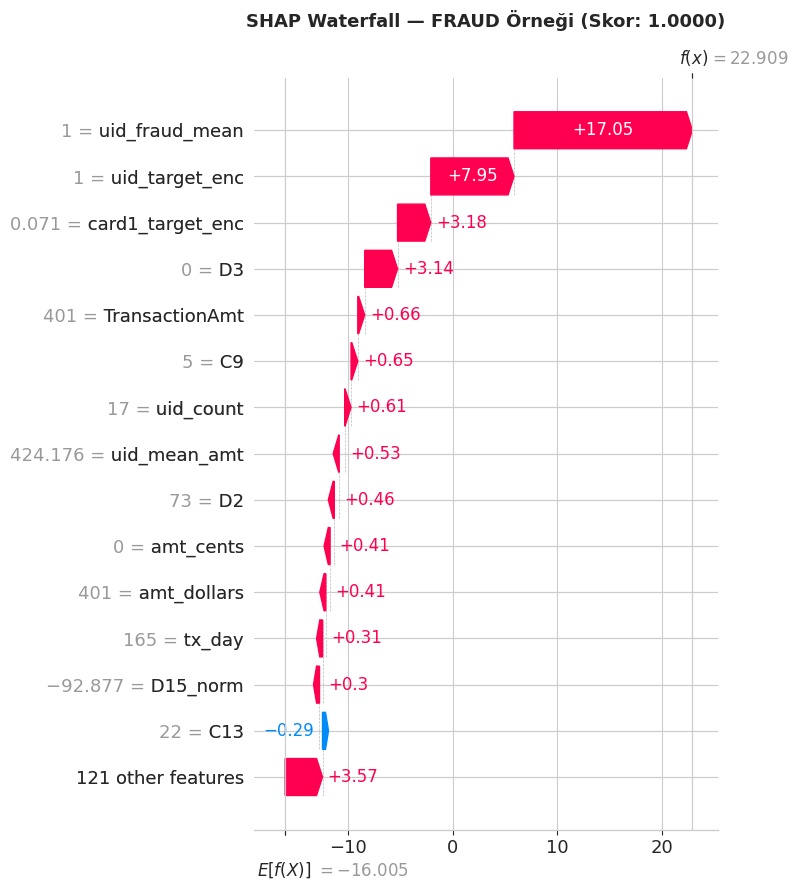

Kaydedildi: /content/drive/My Drive/Bitirme/15-Mayıs-Cuma/shap_waterfall_fraud.png


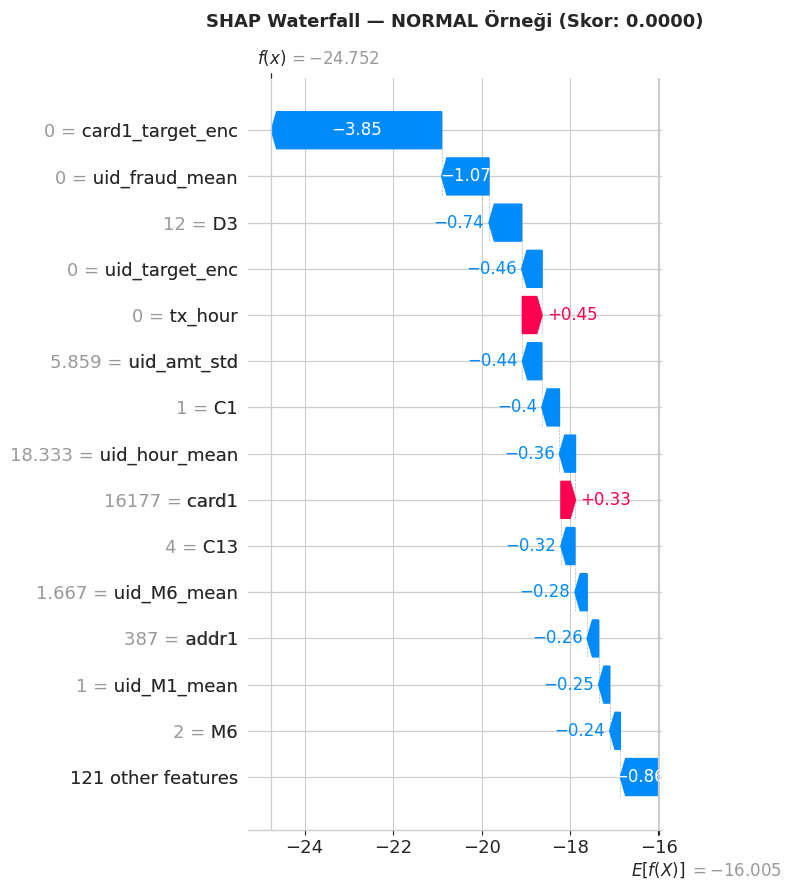

Kaydedildi: /content/drive/My Drive/Bitirme/15-Mayıs-Cuma/shap_waterfall_normal.png
[SURE] Waterfall grafikleri: 2.7 sn


In [22]:
_t_start = time.time()

# Base value
if isinstance(explainer.expected_value, (list, np.ndarray)):
    base_value = explainer.expected_value[1]
else:
    base_value = explainer.expected_value

# Fraud ornegi: SHAP orneklemindeki fraud islemlerden en yuksek fraud skorluysu sec
proba_shap = lgb_model.predict_proba(X_shap)[:, 1]
fraud_mask_shap  = (y_shap == 1).values
normal_mask_shap = (y_shap == 0).values

# En guvenli fraud (yuksek skor)
fraud_proba_scores = np.where(fraud_mask_shap, proba_shap, -1)
fraud_ex_idx = int(np.argmax(fraud_proba_scores))

# En guvenli normal (dusuk skor)
normal_proba_scores = np.where(normal_mask_shap, proba_shap, 2.0)
normal_ex_idx = int(np.argmin(normal_proba_scores))

print(f'Fraud  ornegi  : idx={fraud_ex_idx}, skor={proba_shap[fraud_ex_idx]:.4f}, gercek={y_shap.iloc[fraud_ex_idx]}')
print(f'Normal ornegi  : idx={normal_ex_idx}, skor={proba_shap[normal_ex_idx]:.4f}, gercek={y_shap.iloc[normal_ex_idx]}')

# ── Fraud waterfall ────────────────────────────────────────────────────────────
fraud_exp = shap.Explanation(
    values=shap_vals[fraud_ex_idx],
    base_values=base_value,
    data=X_shap.iloc[fraud_ex_idx].values,
    feature_names=list(X_shap.columns),
)

fig, ax = plt.subplots(figsize=(12, 8))
shap.plots.waterfall(fraud_exp, max_display=15, show=False)
plt.title(
    f'SHAP Waterfall — FRAUD Örneği (Skor: {proba_shap[fraud_ex_idx]:.4f})',
    fontsize=13, fontweight='bold', pad=15
)
plt.tight_layout()
wf_fraud_path = SAVE_BASE + 'shap_waterfall_fraud.png'
plt.savefig(wf_fraud_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Kaydedildi: {wf_fraud_path}')

# ── Normal waterfall ───────────────────────────────────────────────────────────
normal_exp = shap.Explanation(
    values=shap_vals[normal_ex_idx],
    base_values=base_value,
    data=X_shap.iloc[normal_ex_idx].values,
    feature_names=list(X_shap.columns),
)

fig, ax = plt.subplots(figsize=(12, 8))
shap.plots.waterfall(normal_exp, max_display=15, show=False)
plt.title(
    f'SHAP Waterfall — NORMAL Örneği (Skor: {proba_shap[normal_ex_idx]:.4f})',
    fontsize=13, fontweight='bold', pad=15
)
plt.tight_layout()
wf_normal_path = SAVE_BASE + 'shap_waterfall_normal.png'
plt.savefig(wf_normal_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Kaydedildi: {wf_normal_path}')
print(f'[SURE] Waterfall grafikleri: {time.time()-_t_start:.1f} sn')

## 23. SHAP Force Plot — İnteraktif Görselleştirme (Opsiyonel)

Beeswarm/Waterfall kaydedildi. Force plot Colab'da inline görüntüleme için:

In [23]:
# Force plot — Colab notebook icinde goruntuler (PNG olarak kaydedilmez)
shap.initjs()

print('--- FRAUD ornegi force plot ---')
display(
    shap.force_plot(
        base_value,
        shap_vals[fraud_ex_idx],
        X_shap.iloc[fraud_ex_idx],
        feature_names=list(X_shap.columns),
    )
)

print('--- NORMAL ornegi force plot ---')
display(
    shap.force_plot(
        base_value,
        shap_vals[normal_ex_idx],
        X_shap.iloc[normal_ex_idx],
        feature_names=list(X_shap.columns),
    )
)

--- FRAUD ornegi force plot ---


--- NORMAL ornegi force plot ---


## 24. SHAP Özet ve Yorumlama

In [24]:
total_elapsed = time.time() - _t0_total

print('=' * 65)
print('  SHAP ANALİZİ ÖZET — LightGBM Optuna V2')
print('=' * 65)
print(f'  Model          : LightGBM Optuna V2 (AUC-PR=0.6307, ROC=0.9179)')
print(f'  SHAP Orneklem  : {len(X_shap):,} islem ({y_shap.sum()} fraud + {(y_shap==0).sum()} normal)')
print()
print('  TOP 10 OZELLIK (Mean |SHAP|):')
print(f'  {"Sira":<5} {"Ozellik":<35} {"Mean |SHAP|":>12}')
print('  ' + '-' * 55)
for i, row in shap_importance.head(10).iterrows():
    print(f'  {i+1:<5} {row["feature"]:<35} {row["mean_abs_shap"]:>12.5f}')
print()
print('  Kaydedilen dosyalar:')
for fname in ['shap_beeswarm.png', 'shap_bar.png',
              'shap_waterfall_fraud.png', 'shap_waterfall_normal.png',
              'shap_top_features.csv']:
    print(f'    {SAVE_BASE}{fname}')
print()
print(f'  Toplam sure    : {total_elapsed/60:.1f} dakika')
print('=' * 65)

  SHAP ANALİZİ ÖZET — LightGBM Optuna V2
  Model          : LightGBM Optuna V2 (AUC-PR=0.6307, ROC=0.9179)
  SHAP Orneklem  : 2,000 islem (500 fraud + 1500 normal)

  TOP 10 OZELLIK (Mean |SHAP|):
  Sira  Ozellik                              Mean |SHAP|
  -------------------------------------------------------
  1     card1_target_enc                         2.53680
  2     uid_fraud_mean                           1.48061
  3     C13                                      0.64793
  4     C1                                       0.63763
  5     uid_target_enc                           0.61418
  6     D1n                                      0.45475
  7     D3                                       0.45475
  8     C14                                      0.42797
  9     tx_day                                   0.30259
  10    D4_norm                                  0.28836

  Kaydedilen dosyalar:
    /content/drive/My Drive/Bitirme/15-Mayıs-Cuma/shap_beeswarm.png
    /content/drive/My Driv